In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/telco_clean.csv")
print(df.shape)

(7043, 21)


In [2]:
df.groupby("Contract")["Churn"].agg(customers="count", churn_rate="mean").round(3)

,customers,churn_rate
Contract,,
Month-to-month,3875,0.427
One year,1473,0.113
Two year,1695,0.028


In [3]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)
df.groupby("tenure_group", observed=True)["Churn"].agg(customers="count", churn_rate="mean").round(3)

,customers,churn_rate
tenure_group,,
0-6,1481,0.529
7-12,705,0.359
13-24,1024,0.287
25-48,1594,0.204
49-72,2239,0.095


In [4]:
df.groupby("PaymentMethod")["Churn"].agg(customers="count", churn_rate="mean").round(3)

,customers,churn_rate
PaymentMethod,,
Bank transfer (automatic),1544,0.167
Credit card (automatic),1522,0.152
Electronic check,2365,0.453
Mailed check,1612,0.191


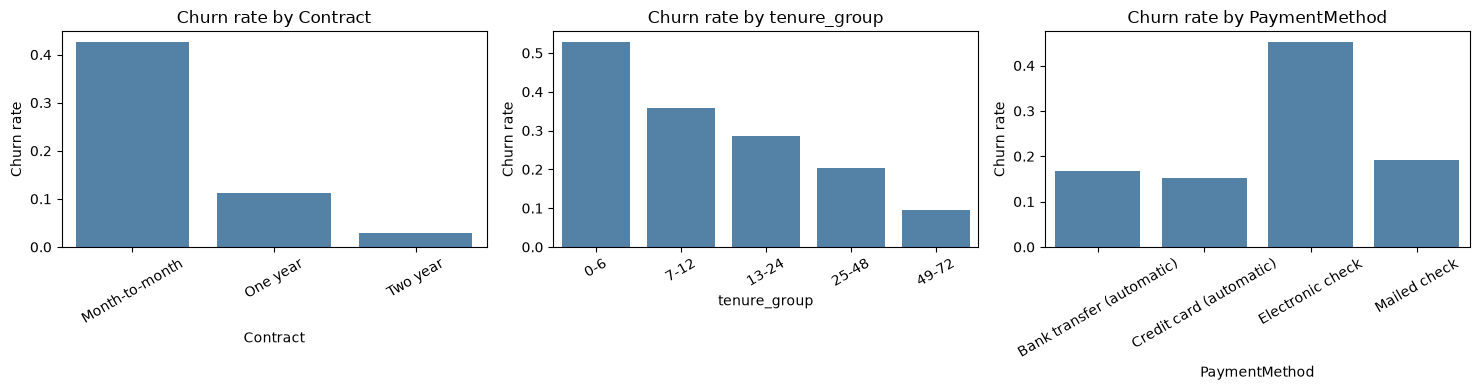

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "tenure_group", "PaymentMethod"]):
    rates = df.groupby(col, observed=True)["Churn"].mean()
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color="steelblue")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [6]:
from scipy.stats import chi2_contingency
import numpy as np

table = pd.crosstab(df["Contract"], df["Churn"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("p-value:", p)

# Effect size: Cramer's V (0 = no relationship, 1 = perfect)
n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print("Cramer's V:", round(cramers_v, 3))

Churn              0     1
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48
p-value: 5.863038300673391e-258
Cramer's V: 0.41
